<a href="https://colab.research.google.com/github/RETNO26MA41D019/EDA-Cart-Abandonment/blob/main/Cart_Abandonment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Sel 1: Instalasi pustaka tambahan
!pip install -q kagglehub xgboost shap scikit-learn seaborn matplotlib pandas numpy scipy

In [2]:
# Sel 2: Import pustaka & unduh dataset dari Kaggle
import os
import warnings
warnings.filterwarnings('ignore')

import kagglehub
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    f1_score, recall_score, precision_score, RocCurveDisplay
)

import xgboost as xgb
import shap

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

# Unduh dataset Online Shoppers Purchasing Intention dari Kaggle
path = kagglehub.dataset_download("imakash3011/online-shoppers-purchasing-intention-dataset")
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0])

df_raw = pd.read_csv(file_path)
print(f"Dataset berhasil dimuat dari: {file_path}")
print(f"Dimensi Dataset: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")

100%|██████████| 252k/252k [00:00<00:00, 803kB/s]

Extracting files...
Dataset berhasil dimuat dari: /root/.cache/kagglehub/datasets/imakash3011/online-shoppers-purchasing-intention-dataset/versions/1/online_shoppers_intention.csv
Dimensi Dataset: 12330 baris x 18 kolom


Tahap 1: Inspeksi Struktur, Kualitas Data, & Duplikasi (Data Understanding)
Dataset ini terdiri atas 12.330 sesi pengguna dan 18 kolom (10 fitur numerik perilaku halaman/Google Analytics dan 8 fitur kategorikal/boolean dengan target Revenue yang merepresentasikan konversi pembelian vs. non-konversi/pengabaian sesi).

In [3]:
# Sel 3: Audit struktur, tipe data, missing values, dan duplikasi
print("=== 1. INFORMASI STRUKTUR & TIPE DATA ===")
print(df_raw.info())

print("\n=== 2. PEMERIKSAAN MISSING VALUES ===")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ditemukan nilai kosong (0 NaN).")

print("\n=== 3. PEMERIKSAAN BARIS DUPLIKAT ===")
dup_count = df_raw.duplicated().sum()
print(f"Jumlah baris duplikat penuh: {dup_count} ({dup_count/len(df_raw)*100:.2f}%)")

# Eliminasi baris duplikat penuh agar tidak membiaskan distribusi statistik
df = df_raw.drop_duplicates().copy()
print(f"Dimensi setelah deduplikasi: {df.shape[0]} baris x {df.shape[1]} kolom")

# Konversi kolom boolean menjadi integer (0/1) untuk konsistensi pemodelan
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)  # Target Y: 1 = Purchased, 0 = Non-Purchase

=== 1. INFORMASI STRUKTUR & TIPE DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non

Tahap 2: Analisis Statistika Deskriptif, Skewness, & Kurtosis
Mengevaluasi ukuran pemusatan (mean, median), penyebaran (std, IQR), serta kemiringan distribusi (skewness) untuk menentukan strategi transformasi dan deteksi pencilan.

In [4]:
# Sel 4: Tabel Statistika Deskriptif Lengkap
num_cols = [
    'Administrative', 'Administrative_Duration',
    'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay'
]

desc = df[num_cols].describe().T
desc['median'] = df[num_cols].median()
desc['iqr'] = desc['75%'] - desc['25%']
desc['skewness'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()

print("=== STATISTIKA DESKRIPTIF VARIABEL NUMERIK ===")
display(desc[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'iqr', 'skewness', 'kurtosis']].round(3))

=== STATISTIKA DESKRIPTIF VARIABEL NUMERIK ===


,count,mean,std,min,25%,median,75%,max,iqr,skewness,kurtosis
Administrative,12205.0,2.339,3.330,0.0,0.000,1.000,4.000,27.000,4.000,1.947,4.641
Administrative_Duration,12205.0,81.646,177.492,0.0,0.000,9.000,94.700,3398.750,94.700,5.592,50.137
Informational,12205.0,0.509,1.276,0.0,0.000,0.000,0.000,24.000,0.000,4.014,26.659
Informational_Duration,12205.0,34.825,141.425,0.0,0.000,0.000,0.000,2549.375,0.000,7.540,75.534
ProductRelated,12205.0,32.046,44.594,0.0,8.000,18.000,38.000,705.000,30.000,4.333,31.073
ProductRelated_Duration,12205.0,1206.982,1919.601,0.0,193.000,608.943,1477.155,63973.522,1284.155,7.253,136.681
BounceRates,12205.0,0.020,0.045,0.0,0.000,0.003,0.017,0.200,0.017,3.162,9.334
ExitRates,12205.0,0.041,0.046,0.0,0.014,0.025,0.049,0.200,0.034,2.235,4.642
PageValues,12205.0,5.950,18.654,0.0,0.000,0.000,0.000,361.764,0.000,6.351,64.998
SpecialDay,12205.0,0.062,0.200,0.0,0.000,0.000,0.000,1.000,0.000,3.286,9.798


Tahap 3: Visualisasi Univariat, Bivariat, & Uji Hipotesis ($\alpha = 0,05$)Menguji secara objektif apakah perbedaan karakteristik antara sesi yang berujung pembelian (Revenue = 1) dan sesi yang ditinggalkan (Revenue = 0) signifikan secara statistik menggunakan Uji Mann-Whitney U (numerik) dan Uji Chi-Square (kategorikal).

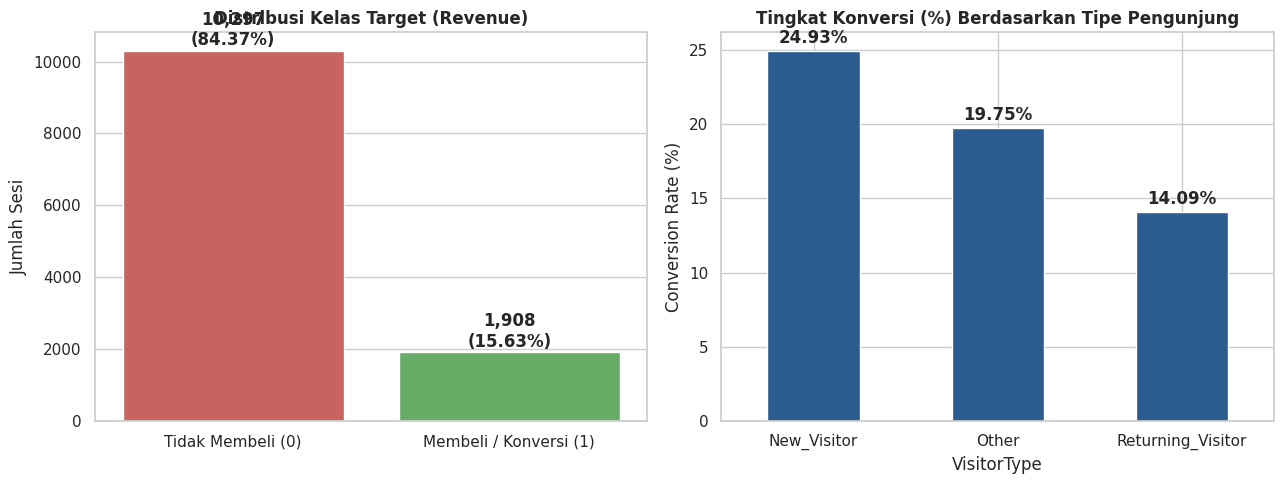

In [5]:
# Sel 5: Distribusi Variabel Target (Class Imbalance Check)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

target_counts = df['Revenue'].value_counts()
target_pct = df['Revenue'].value_counts(normalize=True) * 100

sns.barplot(x=['Tidak Membeli (0)', 'Membeli / Konversi (1)'], y=target_counts.values, ax=axes[0], palette=['#d9534f', '#5cb85c'])
axes[0].set_title('Distribusi Kelas Target (Revenue)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Sesi')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 150, f"{v:,}\n({target_pct.values[i]:.2f}%)", ha='center', fontweight='bold')

# Tingkat Konversi berdasarkan Tipe Pengunjung (VisitorType)
ct_visitor = pd.crosstab(df['VisitorType'], df['Revenue'], normalize='index') * 100
ct_visitor[1].sort_values(ascending=False).plot(kind='bar', ax=axes[1], color='#2b5c8f')
axes[1].set_title('Tingkat Konversi (%) Berdasarkan Tipe Pengunjung', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Conversion Rate (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
for i, v in enumerate(ct_visitor[1].sort_values(ascending=False).values):
    axes[1].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# Sel 6: Uji Hipotesis Bivariat (Mann-Whitney U & Chi-Square pada alpha = 0.05)
print("=== UJI MANN-WHITNEY U (NUMERIK VS REVENUE) ===")
mw_results = []
for col in num_cols:
    g0 = df[df['Revenue'] == 0][col]
    g1 = df[df['Revenue'] == 1][col]
    stat, p_val = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    mw_results.append({
        'Fitur': col,
        'Median_NoBuy(0)': round(g0.median(), 4),
        'Median_Buy(1)': round(g1.median(), 4),
        'Mean_NoBuy(0)': round(g0.mean(), 4),
        'Mean_Buy(1)': round(g1.mean(), 4),
        'p_value': f"{p_val:.4e}",
        'Signifikan (a=0.05)': 'Ya' if p_val < 0.05 else 'Tidak'
    })
display(pd.DataFrame(mw_results))

print("\n=== UJI CHI-SQUARE (KATEGORIKAL VS REVENUE) ===")
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
chi_results = []
for col in cat_cols:
    ct = pd.crosstab(df[col], df['Revenue'])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    chi_results.append({
        'Fitur': col,
        'Chi2_Stat': round(chi2, 3),
        'DoF': dof,
        'p_value': f"{p_val:.4e}",
        'Signifikan (a=0.05)': 'Ya' if p_val < 0.05 else 'Tidak'
    })
display(pd.DataFrame(chi_results))

=== UJI MANN-WHITNEY U (NUMERIK VS REVENUE) ===


,Fitur,Median_NoBuy(0),Median_Buy(1),Mean_NoBuy(0),Mean_Buy(1),p_value,Signifikan (a=0.05)
0,Administrative,1.0000,2.0000,2.1434,3.3936,8.9046e-74,Ya
1,Administrative_Duration,0.0000,52.3667,74.6353,119.4832,2.2200e-70,Ya
2,Informational,0.0000,0.0000,0.4573,0.7862,4.3654e-35,Ya
3,Informational_Duration,0.0000,0.0000,30.6033,57.6114,4.0532e-34,Ya
4,ProductRelated,16.0000,29.0000,29.0504,48.2102,3.6936e-102,Ya
5,ProductRelated_Duration,526.0000,1109.9062,1082.9769,1876.2096,4.1833e-122,Ya
6,BounceRates,0.0039,0.0000,0.0232,0.0051,1.0601e-56,Ya
7,ExitRates,0.0284,0.0160,0.0455,0.0196,3.0299e-169,Ya
8,PageValues,0.0000,16.7581,2.0000,27.2645,0.0000e+00,Ya
9,SpecialDay,0.0000,0.0000,0.0691,0.0232,1.7405e-22,Ya



=== UJI CHI-SQUARE (KATEGORIKAL VS REVENUE) ===


,Fitur,Chi2_Stat,DoF,p_value,Signifikan (a=0.05)
0,Month,376.280,9,1.5668e-75,Ya
1,OperatingSystems,75.070,7,1.3880e-13,Ya
2,Browser,29.119,12,3.7828e-03,Ya
3,Region,9.679,8,2.8826e-01,Tidak
4,TrafficType,359.225,19,1.2633e-64,Ya
5,VisitorType,130.668,2,4.2256e-29,Ya
6,Weekend,9.205,1,2.4138e-03,Ya


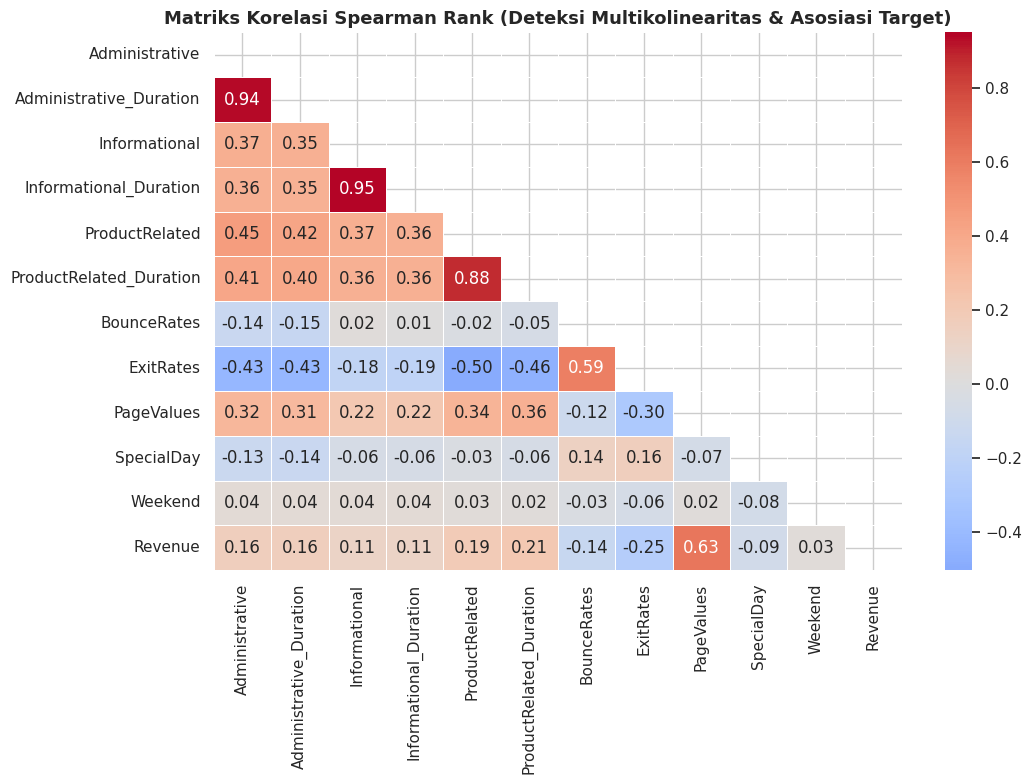

In [7]:
# Sel 7: Analisis Korelasi & Multikolinearitas (Spearman Rank)
plt.figure(figsize=(11, 8))
corr_matrix = df[num_cols + ['Weekend', 'Revenue']].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matriks Korelasi Spearman Rank (Deteksi Multikolinearitas & Asosiasi Target)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Tahap 4: Penanganan Pencilan, Rekayasa Fitur (Feature Engineering), & Preprocessing
Menambahkan fitur turunan berbasis perilaku navigasi sesi serta menyiapkan dua jalur pipeline (jalur log-transform + StandardScaler untuk baseline Logistic Regression dan jalur fitur asli + engineered features untuk XGBoost).

In [8]:
# Sel 8: Feature Engineering Berbasis Domain E-Commerce
df_fe = df.copy()

# 1. Total halaman yang dikunjungi dalam satu sesi
df_fe['Total_Pages'] = df_fe['Administrative'] + df_fe['Informational'] + df_fe['ProductRelated']

# 2. Total durasi sesi keseluruhan (detik)
df_fe['Total_Duration'] = (
    df_fe['Administrative_Duration'] +
    df_fe['Informational_Duration'] +
    df_fe['ProductRelated_Duration']
)

# 3. Rata-rata waktu tinggal per halaman (Dwell Time per Page)
df_fe['Avg_Time_Per_Page'] = df_fe['Total_Duration'] / (df_fe['Total_Pages'] + 1e-5)

# 4. Rasio fokus pada halaman produk dibandingkan total halaman
df_fe['Product_Page_Ratio'] = df_fe['ProductRelated'] / (df_fe['Total_Pages'] + 1e-5)

# 5. Indikator apakah pengguna melihat halaman bernilai komersial (PageValues > 0)
df_fe['Has_PageValue'] = (df_fe['PageValues'] > 0).astype(int)

# Konversi kode integer kategorikal menjadi tipe string/kategori sebelum One-Hot Encoding
nominal_features = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
for col in nominal_features:
    df_fe[col] = df_fe[col].astype(str)

numeric_features = num_cols + [
    'Weekend', 'Total_Pages', 'Total_Duration',
    'Avg_Time_Per_Page', 'Product_Page_Ratio', 'Has_PageValue'
]

X = df_fe[numeric_features + nominal_features]
y = df_fe['Revenue']

# Stratified Train-Test Split (80% Train, 20% Test) agar proporsi kelas tetap terjaga
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Ukuran Training Set: {X_train.shape[0]} baris | Test Set: {X_test.shape[0]} baris")
print(f"Proporsi Kelas Positif (Train): {y_train.mean()*100:.2f}% | (Test): {y_test.mean()*100:.2f}%")

Ukuran Training Set: 9764 baris | Test Set: 2441 baris
Proporsi Kelas Positif (Train): 15.63% | (Test): 15.65%


Tahap 5: Pemodelan XGBoost Classifier & Perbandingan Baseline
Karena dataset mengalami class imbalance (~84,4% kelas 0 vs ~15,6% kelas 1), model XGBoost dikonfigurasi menggunakan parameter scale_pos_weight untuk memberikan penalti kesalahan lebih tinggi pada kelas minoritas tanpa merusak distribusi data asli, lalu dibandingkan dengan model baseline Logistic Regression.

In [9]:
# Sel 9: Pipeline Preprocessing & Pelatihan Model (Logistic Regression Baseline vs XGBoost)

# Preprocessor untuk Logistic Regression (dengan Log1p untuk fitur right-skewed + StandardScaler)
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(lambda x: np.log1p(np.maximum(x, 0)))

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('log', log_transformer), ('scaler', StandardScaler())]), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), nominal_features)
    ]
)

# Preprocessor untuk XGBoost (tanpa scaling agar nilai fitur asli terbaca jelas di SHAP)
preprocessor_xgb = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_features)
    ]
)

# 1. Baseline: Logistic Regression (Balanced)
model_lr = Pipeline([
    ('prep', preprocessor_lr),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
model_lr.fit(X_train, y_train)

# 2. Model Utama: XGBoost Classifier dengan Cost-Sensitive Weighting
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count

X_train_enc = preprocessor_xgb.fit_transform(X_train)
X_test_enc = preprocessor_xgb.transform(X_test)
feature_names = preprocessor_xgb.get_feature_names_out()

# Rapikan nama fitur agar mudah dibaca di grafik SHAP
clean_feature_names = [name.replace('num__', '').replace('cat__', '') for name in feature_names]
X_train_df = pd.DataFrame(X_train_enc.toarray() if hasattr(X_train_enc, "toarray") else X_train_enc, columns=clean_feature_names)
X_test_df = pd.DataFrame(X_test_enc.toarray() if hasattr(X_test_enc, "toarray") else X_test_enc, columns=clean_feature_names)

xgb_clf = xgb.XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_clf.fit(X_train_df, y_train)

# Evaluasi Kinerja Kedua Model pada Test Set
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'ROC-AUC': round(roc_auc_score(y_true, y_prob), 4),
        'F1-Score (Kelas 1)': round(f1_score(y_true, y_pred), 4),
        'Recall / Sensitivity': round(recall_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4)
    }

y_pred_lr = model_lr.predict(X_test)
y_prob_lr = model_lr.predict_proba(X_test)[:, 1]

y_pred_xgb = xgb_clf.predict(X_test_df)
y_prob_xgb = xgb_clf.predict_proba(X_test_df)[:, 1]

eval_df = pd.DataFrame([
    evaluate_model("Logistic Regression (Baseline)", y_test, y_pred_lr, y_prob_lr),
    evaluate_model("XGBoost Classifier (Cost-Sensitive)", y_test, y_pred_xgb, y_prob_xgb)
])
print("=== PERBANDINGAN PERFORMA MODEL PADA DATA UJI ===")
display(eval_df)

print("\n=== CLASSIFICATION REPORT: XGBOOST CLASSIFIER ===")
print(classification_report(y_test, y_pred_xgb, target_names=['No Purchase (0)', 'Purchase (1)']))

=== PERBANDINGAN PERFORMA MODEL PADA DATA UJI ===


,Model,ROC-AUC,F1-Score (Kelas 1),Recall / Sensitivity,Precision
0,Logistic Regression (Baseline),0.9268,0.6646,0.8508,0.5453
1,XGBoost Classifier (Cost-Sensitive),0.9343,0.6638,0.8089,0.5628



=== CLASSIFICATION REPORT: XGBOOST CLASSIFIER ===
                 precision    recall  f1-score   support

No Purchase (0)       0.96      0.88      0.92      2059
   Purchase (1)       0.56      0.81      0.66       382

       accuracy                           0.87      2441
      macro avg       0.76      0.85      0.79      2441
   weighted avg       0.90      0.87      0.88      2441



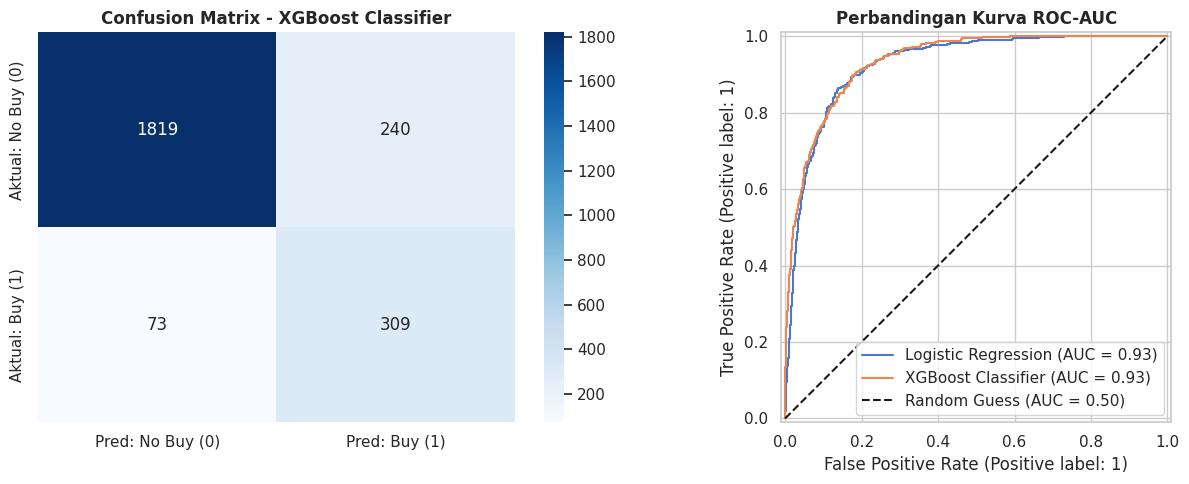

In [10]:
# Sel 10: Visualisasi Confusion Matrix & Kurva ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: No Buy (0)', 'Pred: Buy (1)'],
            yticklabels=['Aktual: No Buy (0)', 'Aktual: Buy (1)'])
axes[0].set_title('Confusion Matrix - XGBoost Classifier', fontsize=12, fontweight='bold')

RocCurveDisplay.from_predictions(y_test, y_prob_lr, name='Logistic Regression', ax=axes[1])
RocCurveDisplay.from_predictions(y_test, y_prob_xgb, name='XGBoost Classifier', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')
axes[1].set_title('Perbandingan Kurva ROC-AUC', fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

Tahap 6: Explainable AI (XAI) Menggunakan SHAP (TreeExplainer)
Mengungkap mekanisme internal model XGBoost baik secara global (fitur apa yang paling memengaruhi konversi di seluruh populasi) maupun lokal (mengapa satu sesi spesifik diprediksi akan membeli atau batal membeli).

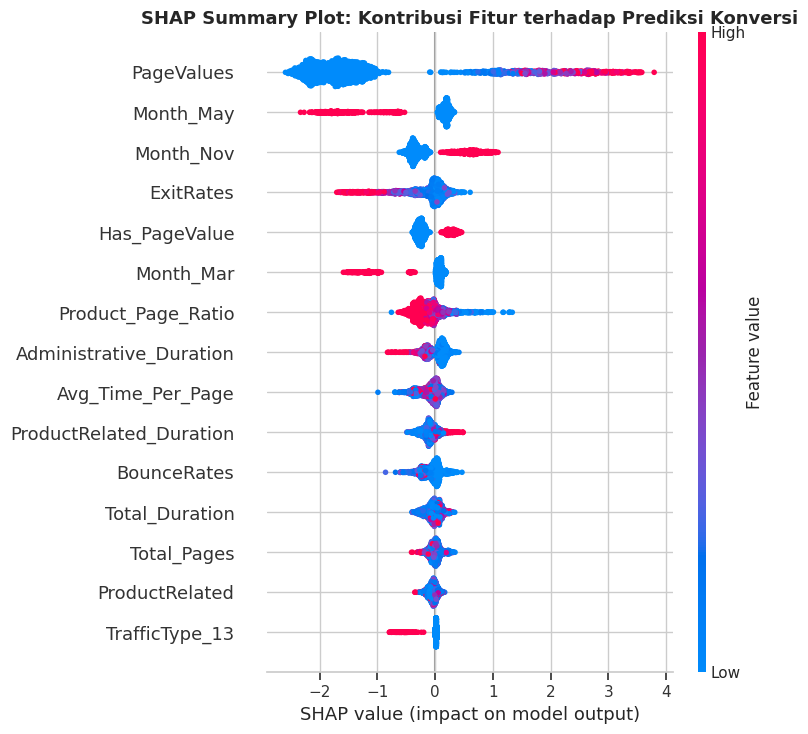

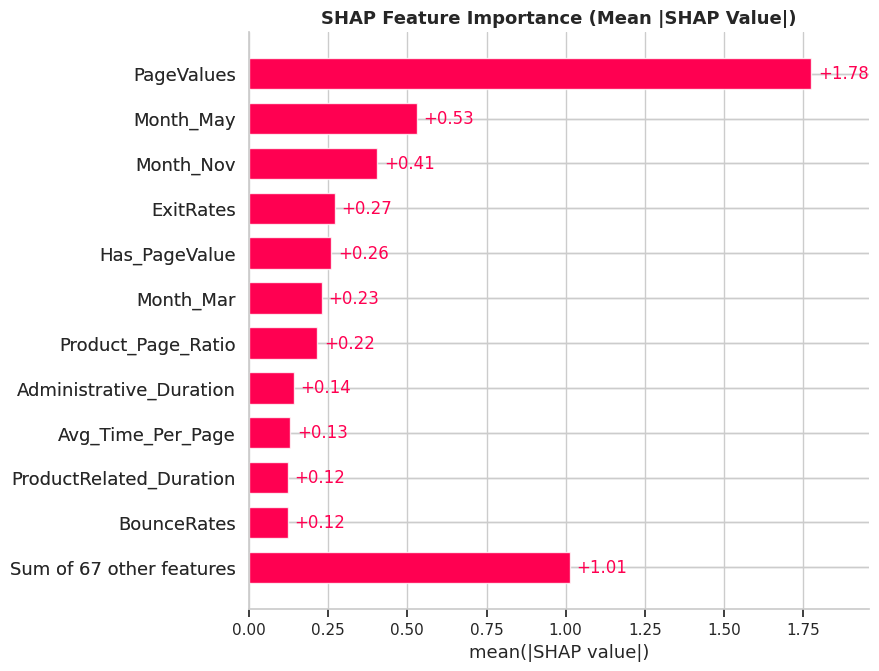

In [11]:
# Sel 11: Perhitungan Nilai SHAP & Visualisasi Global (Summary Plot & Bar Plot)
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer(X_test_df)

# 1. SHAP Summary Plot (Beeswarm) - Arah & magnitudo dampak fitur secara global
plt.figure(figsize=(10, 6))
plt.title("SHAP Summary Plot: Kontribusi Fitur terhadap Prediksi Konversi", fontsize=13, fontweight='bold')
shap.summary_plot(shap_values, X_test_df, max_display=15, show=True)

# 2. SHAP Bar Plot - Peringkat rata-rata kepentingan fitur absolut
plt.figure(figsize=(10, 5))
plt.title("SHAP Feature Importance (Mean |SHAP Value|)", fontsize=13, fontweight='bold')
shap.plots.bar(shap_values, max_display=12, show=True)

--- Analisis Lokal Sesi #21 (Aktual: Membeli | Probabilitas Prediksi: 96.00%) ---


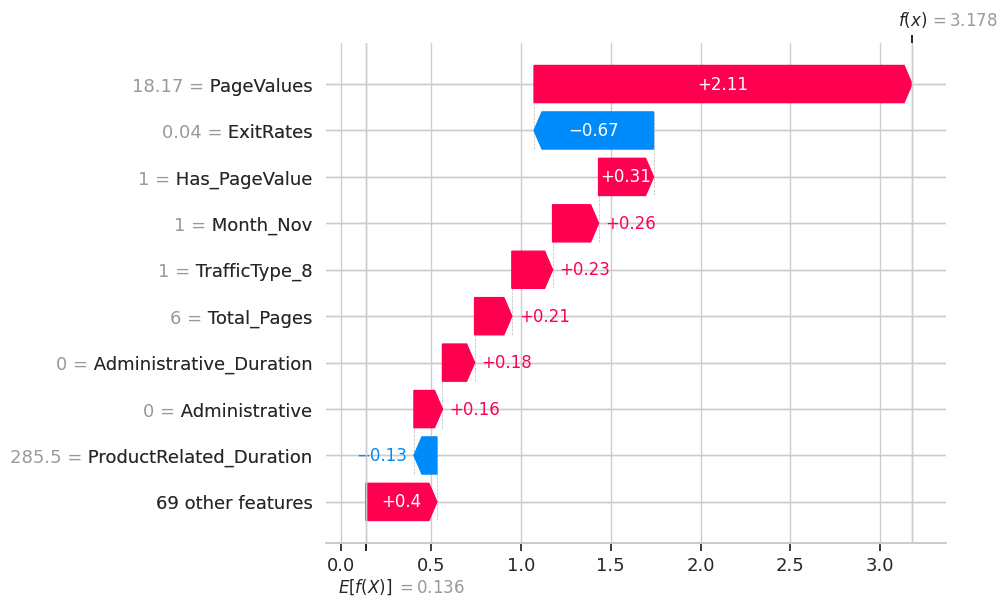


--- Analisis Lokal Sesi #0 (Aktual: Tidak Membeli | Probabilitas Prediksi: 10.11%) ---


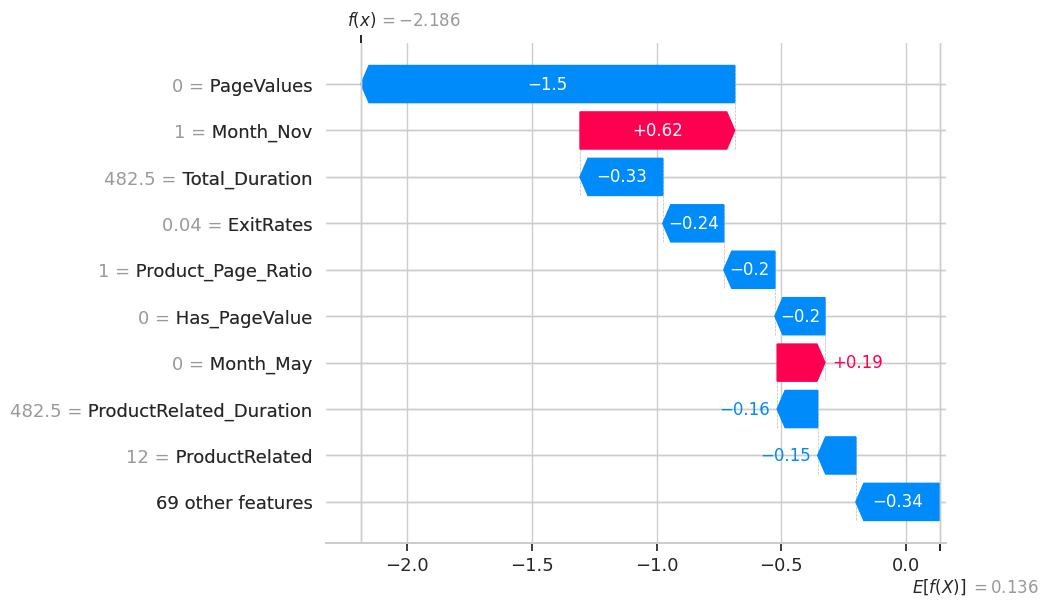

In [12]:
# Sel 12: Interpretasi Lokal Per Sesi (SHAP Waterfall Plot)
# Mengambil 1 contoh sesi yang diprediksi konversi tinggi dan 1 sesi yang diprediksi batal/tidak membeli
idx_buy = np.where((y_test.values == 1) & (y_pred_xgb == 1))[0][0]
idx_nobuy = np.where((y_test.values == 0) & (y_pred_xgb == 0))[0][0]

print(f"--- Analisis Lokal Sesi #{idx_buy} (Aktual: Membeli | Probabilitas Prediksi: {y_prob_xgb[idx_buy]:.2%}) ---")
shap.plots.waterfall(shap_values[idx_buy], max_display=10)

print(f"\n--- Analisis Lokal Sesi #{idx_nobuy} (Aktual: Tidak Membeli | Probabilitas Prediksi: {y_prob_xgb[idx_nobuy]:.2%}) ---")
shap.plots.waterfall(shap_values[idx_nobuy], max_display=10)